## Bussiness Problem

* Businesses manage many products with different prices, stock levels, and sales demand. It is difficult to identify which products sell quickly, which products have excess stock, and which products have low demand.

* The Inventory and Product Grouping System uses Machine Learning to group similar products based on their stock levels, sales, prices, and demand. These groups help businesses understand their products better and make better stock management decisions.

In [1]:
import pandas as pd
import numpy as np

In [2]:
df = pd.read_csv(r"D:\Inventory_Product_Grouping_System\data\sales_data.csv")
df.head()

,Date,Store ID,Product ID,Category,Region,Inventory Level,Units Sold,Units Ordered,Price,Discount,Weather Condition,Promotion,Competitor Pricing,Seasonality,Epidemic,Demand
0,2022-01-01,S001,P0001,Electronics,North,195,102,252,72.72,5,Snowy,0,85.73,Winter,0,115
1,2022-01-01,S001,P0002,Clothing,North,117,117,249,80.16,15,Snowy,1,92.02,Winter,0,229
2,2022-01-01,S001,P0003,Clothing,North,247,114,612,62.94,10,Snowy,1,60.08,Winter,0,157
3,2022-01-01,S001,P0004,Electronics,North,139,45,102,87.63,10,Snowy,0,85.19,Winter,0,52
4,2022-01-01,S001,P0005,Groceries,North,152,65,271,54.41,0,Snowy,0,51.63,Winter,0,59


In [3]:
df.shape

(76000, 16)

In [4]:
df.columns.tolist()

['Date',
 'Store ID',
 'Product ID',
 'Category',
 'Region',
 'Inventory Level',
 'Units Sold',
 'Units Ordered',
 'Price',
 'Discount',
 'Weather Condition',
 'Promotion',
 'Competitor Pricing',
 'Seasonality',
 'Epidemic',
 'Demand']

* Date : The date on which the store's product and sales information was recorded.
* Store Id : Identifies the store where the record was collected.
* Product Id : Uniquely identifies a product.
* Category : Specifies the type of product.
* Region : Identifies the geographical region of the store.
* Inventory Level : The recorded number of units available in inventory.
* Units Sold : The number of product units sold during the recorded period.
* Units Ordered : The number of units ordered or replenished, as represented in the dataset.
* Price : The recorded selling price of a product.
* Discount : The discount applied to the product, represented as a numeric value.
* Weather Condition : Describes the weather recorded for that observation.
* Promption : Indicates whether a promotion was active.
* Competitor Pricing : The recorded price of a comparable product from a competitor.
* Seasonality : Identifies the season associated with the observation.
* Epidemic : A binary indicator for whether an epidemic-related condition is recorded.it May help explain unusual changes in sales or demand. Its exact meaning depends on the dataset's documentation.
* Demand : A numerical value representing product demand.

In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 76000 entries, 0 to 75999
Data columns (total 16 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   Date                76000 non-null  str    
 1   Store ID            76000 non-null  str    
 2   Product ID          76000 non-null  str    
 3   Category            76000 non-null  str    
 4   Region              76000 non-null  str    
 5   Inventory Level     76000 non-null  int64  
 6   Units Sold          76000 non-null  int64  
 7   Units Ordered       76000 non-null  int64  
 8   Price               76000 non-null  float64
 9   Discount            76000 non-null  int64  
 10  Weather Condition   76000 non-null  str    
 11  Promotion           76000 non-null  int64  
 12  Competitor Pricing  76000 non-null  float64
 13  Seasonality         76000 non-null  str    
 14  Epidemic            76000 non-null  int64  
 15  Demand              76000 non-null  int64  
dtypes: float64(2), 

In [6]:
df.isnull().sum()

Date                  0
Store ID              0
Product ID            0
Category              0
Region                0
Inventory Level       0
Units Sold            0
Units Ordered         0
Price                 0
Discount              0
Weather Condition     0
Promotion             0
Competitor Pricing    0
Seasonality           0
Epidemic              0
Demand                0
dtype: int64

In [7]:
for col in df.columns:
    print(col)
    print(df[col].unique())
    print("\n")

Date
<StringArray>
['2022-01-01', '2022-01-02', '2022-01-03', '2022-01-04', '2022-01-05',
 '2022-01-06', '2022-01-07', '2022-01-08', '2022-01-09', '2022-01-10',
 ...
 '2024-01-21', '2024-01-22', '2024-01-23', '2024-01-24', '2024-01-25',
 '2024-01-26', '2024-01-27', '2024-01-28', '2024-01-29', '2024-01-30']
Length: 760, dtype: str


Store ID
<StringArray>
['S001', 'S002', 'S003', 'S004', 'S005']
Length: 5, dtype: str


Product ID
<StringArray>
['P0001', 'P0002', 'P0003', 'P0004', 'P0005', 'P0006', 'P0007', 'P0008',
 'P0009', 'P0010', 'P0011', 'P0012', 'P0013', 'P0014', 'P0015', 'P0016',
 'P0017', 'P0018', 'P0019', 'P0020']
Length: 20, dtype: str


Category
<StringArray>
['Electronics', 'Clothing', 'Groceries', 'Toys', 'Furniture']
Length: 5, dtype: str


Region
<StringArray>
['North', 'South', 'East', 'West']
Length: 4, dtype: str


Inventory Level
[ 195  117  247 ... 1308 1466 1359]


Units Sold
[102 117 114  45  65  60  81  42  88  70  51 121 113  55  78  59  61  36
 119 167 111 103  

In [8]:
for col in df.columns:
    print(col)
    print(df[col].nunique())

Date
760
Store ID
5
Product ID
20
Category
5
Region
4
Inventory Level
1426
Units Sold
330
Units Ordered
996
Price
15396
Discount
6
Weather Condition
4
Promotion
2
Competitor Pricing
15963
Seasonality
4
Epidemic
2
Demand
340


In [9]:
for col in df.select_dtypes(["str","object"]):
    print(col)
    print(df[col].value_counts())

Date
Date
2022-01-01    100
2022-01-02    100
2022-01-03    100
2022-01-04    100
2022-01-05    100
             ... 
2024-01-26    100
2024-01-27    100
2024-01-28    100
2024-01-29    100
2024-01-30    100
Name: count, Length: 760, dtype: int64
Store ID
Store ID
S001    15200
S002    15200
S003    15200
S004    15200
S005    15200
Name: count, dtype: int64
Product ID
Product ID
P0001    3800
P0002    3800
P0003    3800
P0004    3800
P0005    3800
P0006    3800
P0007    3800
P0008    3800
P0009    3800
P0010    3800
P0011    3800
P0012    3800
P0013    3800
P0014    3800
P0015    3800
P0016    3800
P0017    3800
P0018    3800
P0019    3800
P0020    3800
Name: count, dtype: int64
Category
Category
Groceries      30400
Furniture      13680
Clothing       12160
Toys           10640
Electronics     9120
Name: count, dtype: int64
Region
Region
North    30400
South    15200
East     15200
West     15200
Name: count, dtype: int64
Weather Condition
Weather Condition
Cloudy    24360
Sunny     

In [10]:
df.duplicated().sum()

np.int64(0)

In [11]:
df.describe(include='all')

,Date,Store ID,Product ID,Category,Region,Inventory Level,Units Sold,Units Ordered,Price,Discount,Weather Condition,Promotion,Competitor Pricing,Seasonality,Epidemic,Demand
count,76000,76000,76000,76000,76000,76000.000000,76000.000000,76000.000000,76000.000000,76000.000000,76000,76000.000000,76000.000000,76000,76000.000000,76000.000000
unique,760,5,20,5,4,NaN,NaN,NaN,NaN,NaN,4,NaN,NaN,4,NaN,NaN
top,2022-01-01,S001,P0001,Groceries,North,NaN,NaN,NaN,NaN,NaN,Cloudy,NaN,NaN,Winter,NaN,NaN
freq,100,15200,3800,30400,30400,NaN,NaN,NaN,NaN,NaN,24360,NaN,NaN,21000,NaN,NaN
mean,NaN,NaN,NaN,NaN,NaN,301.062842,88.827316,89.090645,67.726028,9.087039,NaN,0.328947,69.454029,NaN,0.200000,104.317158
std,NaN,NaN,NaN,NaN,NaN,226.510161,43.994525,162.404627,39.377899,7.475781,NaN,0.469834,40.943818,NaN,0.400003,46.964801
min,NaN,NaN,NaN,NaN,NaN,0.000000,0.000000,0.000000,4.740000,0.000000,NaN,0.000000,4.290000,NaN,0.000000,4.000000
25%,NaN,NaN,NaN,NaN,NaN,136.000000,58.000000,0.000000,31.997500,5.000000,NaN,0.000000,32.620000,NaN,0.000000,71.000000
50%,NaN,NaN,NaN,NaN,NaN,227.000000,84.000000,0.000000,64.500000,10.000000,NaN,0.000000,65.700000,NaN,0.000000,100.000000
75%,NaN,NaN,NaN,NaN,NaN,408.000000,114.000000,121.000000,95.830000,10.000000,NaN,1.000000,97.932500,NaN,0.000000,133.000000


In [12]:
selected_columns = [
    "Product ID",
    "Category",
    "Inventory Level",
    "Units Sold",
    "Price",
    "Demand"
]

product_df = df[selected_columns].copy()

product_df.head()

,Product ID,Category,Inventory Level,Units Sold,Price,Demand
0,P0001,Electronics,195,102,72.72,115
1,P0002,Clothing,117,117,80.16,229
2,P0003,Clothing,247,114,62.94,157
3,P0004,Electronics,139,45,87.63,52
4,P0005,Groceries,152,65,54.41,59


* Product id : Identifies which product each record belongs to. Needed to aggregate records by product.
* Category : Identifies product types such as Electronics or Clothing. Helps us understand the resulting groups.
* Inventory Level : Tells us how much stock is available. Helps distinguish high-stock and low-stock products.
* Units sold : Indicates how many units were sold during the recorded period. Helps identify fast- and slow-moving products.
* Price : Represents the product's selling price. Helps distinguish lower- and higher-priced products.
* Demand : Represents the recorded demand level. Helps distinguish products with relatively high or low demand.

In [13]:
print("Original dataset shape:", df.shape)
print("Selected dataset shape:", product_df.shape)

print("\nUnique products:", product_df["Product ID"].nunique())
print("\nProduct categories:")
print(product_df["Category"].value_counts())

Original dataset shape: (76000, 16)
Selected dataset shape: (76000, 6)

Unique products: 20

Product categories:
Category
Groceries      30400
Furniture      13680
Clothing       12160
Toys           10640
Electronics     9120
Name: count, dtype: int64


In [14]:
product_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 76000 entries, 0 to 75999
Data columns (total 6 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   Product ID       76000 non-null  str    
 1   Category         76000 non-null  str    
 2   Inventory Level  76000 non-null  int64  
 3   Units Sold       76000 non-null  int64  
 4   Price            76000 non-null  float64
 5   Demand           76000 non-null  int64  
dtypes: float64(1), int64(3), str(2)
memory usage: 3.5 MB


In [15]:
product_df.duplicated().sum()

np.int64(0)

In [16]:
product_df = product_df.groupby(["Product ID","Category"]).agg({
    "Inventory Level": "mean",
    "Units Sold": "sum",
    "Price": "mean",
    "Demand": "mean"
}).reset_index()

product_df

,Product ID,Category,Inventory Level,Units Sold,Price,Demand
0,P0001,Electronics,245.214474,62075,66.378605,92.814474
1,P0001,Groceries,402.411404,236311,34.754228,121.234211
2,P0001,Toys,206.344737,58428,15.460724,91.439474
3,P0002,Clothing,152.034211,76252,67.103618,124.643421
4,P0002,Electronics,322.567105,62916,38.743184,95.894737
...,...,...,...,...,...,...
59,P0019,Furniture,140.452632,94649,116.926730,73.151316
60,P0019,Groceries,147.575000,74498,55.657329,122.051316
61,P0020,Clothing,478.857895,73031,72.430211,109.657895
62,P0020,Furniture,268.931140,146598,117.617645,73.491228


In [17]:
features = [
    "Inventory Level",
    "Units Sold",
    "Price",
    "Demand"
]

X = product_df[features].copy()

# Display the selected features
X.head()

,Inventory Level,Units Sold,Price,Demand
0,245.214474,62075,66.378605,92.814474
1,402.411404,236311,34.754228,121.234211
2,206.344737,58428,15.460724,91.439474
3,152.034211,76252,67.103618,124.643421
4,322.567105,62916,38.743184,95.894737


In [18]:
from sklearn.preprocessing import StandardScaler

In [19]:
scaler = StandardScaler()
x_scaled = scaler.fit_transform(X)
x_scaled.shape

(64, 4)

In [20]:
scaled_df = pd.DataFrame(
    x_scaled,
    columns=features,
    index=X.index
)

scaled_df

,Inventory Level,Units Sold,Price,Demand
0,-0.358854,-0.626117,-0.114154,-0.514584
1,0.955842,1.887096,-1.015036,1.114101
2,-0.683936,-0.678722,-1.564650,-0.593383
3,-1.138155,-0.421625,-0.093501,1.309476
4,0.288075,-0.613986,-0.901403,-0.338060
...,...,...,...,...
59,-1.235016,-0.156264,1.325809,-1.641445
60,-1.175449,-0.446925,-0.419571,1.160928
61,1.595192,-0.468086,0.058238,0.450682
62,-0.160503,0.593059,1.345491,-1.621965


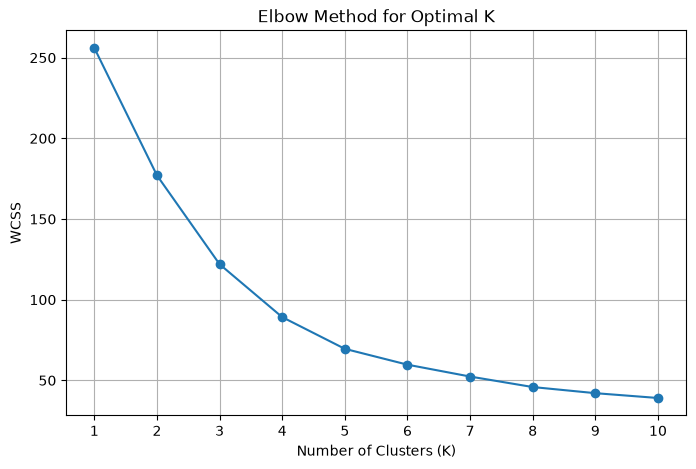

In [22]:
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans

wcss = []

for k in range(1, min(11, len(x_scaled) + 1)):
    kmeans = KMeans(
        n_clusters=k,
        init="k-means++",
        random_state=42,
        n_init=10
    )

    kmeans.fit(x_scaled)
    wcss.append(kmeans.inertia_)

plt.figure(figsize=(8, 5))
plt.plot(
    range(1, min(11, len(x_scaled) + 1)),
    wcss,
    marker="o"
)

plt.title("Elbow Method for Optimal K")
plt.xlabel("Number of Clusters (K)")
plt.ylabel("WCSS")
plt.xticks(range(1, min(11, len(x_scaled) + 1)))
plt.grid(True)
plt.show()

In [24]:
from sklearn.cluster import KMeans

kmeans = KMeans(
    n_clusters=3,
    init="k-means++",
    random_state=42,
    n_init=10
)

kmeans.fit(x_scaled)

print("K-Means model trained successfully!")

K-Means model trained successfully!


In [25]:
# Predict the cluster for each product
product_df["Cluster"] = kmeans.predict(x_scaled)

# Display products with their assigned clusters
product_df.head(10)

,Product ID,Category,Inventory Level,Units Sold,Price,Demand,Cluster
0,P0001,Electronics,245.214474,62075,66.378605,92.814474,2
1,P0001,Groceries,402.411404,236311,34.754228,121.234211,1
2,P0001,Toys,206.344737,58428,15.460724,91.439474,2
3,P0002,Clothing,152.034211,76252,67.103618,124.643421,2
4,P0002,Electronics,322.567105,62916,38.743184,95.894737,2
5,P0002,Groceries,351.909211,157640,38.533204,122.928289,1
6,P0002,Toys,250.734211,62547,30.686461,93.938158,2
7,P0003,Clothing,570.423684,82721,55.996789,123.335526,1
8,P0003,Electronics,146.847368,69498,87.905868,110.521053,2
9,P0003,Furniture,304.830263,51036,129.636013,74.743421,0


In [30]:
cluster_summary = product_df.groupby("Cluster").agg({
    "Category":"first",
    "Inventory Level": "mean",
    "Units Sold": "mean",
    "Price": "mean",
    "Demand": "mean"
}).round(2)

cluster_summary

,Category,Inventory Level,Units Sold,Price,Demand
Cluster,,,,,
0,Furniture,268.86,77415.72,113.52,82.16
1,Groceries,403.44,154218.09,60.38,116.28
2,Electronics,187.88,78712.04,46.64,102.68


In [31]:
cluster_labels = {
    0: "High-Demand, High-Sales Products",
    1: "Lower-Demand, Higher-Price Products",
    2: "Moderate-Demand Products"
}

product_df["Cluster Label"] = product_df["Cluster"].map(cluster_labels)

product_df[[
    "Product ID",
    "Category",
    "Inventory Level",
    "Units Sold",
    "Price",
    "Demand",
    "Cluster",
    "Cluster Label"
]].head(10)

,Product ID,Category,Inventory Level,Units Sold,Price,Demand,Cluster,Cluster Label
0,P0001,Electronics,245.214474,62075,66.378605,92.814474,2,Moderate-Demand Products
1,P0001,Groceries,402.411404,236311,34.754228,121.234211,1,"Lower-Demand, Higher-Price Products"
2,P0001,Toys,206.344737,58428,15.460724,91.439474,2,Moderate-Demand Products
3,P0002,Clothing,152.034211,76252,67.103618,124.643421,2,Moderate-Demand Products
4,P0002,Electronics,322.567105,62916,38.743184,95.894737,2,Moderate-Demand Products
5,P0002,Groceries,351.909211,157640,38.533204,122.928289,1,"Lower-Demand, Higher-Price Products"
6,P0002,Toys,250.734211,62547,30.686461,93.938158,2,Moderate-Demand Products
7,P0003,Clothing,570.423684,82721,55.996789,123.335526,1,"Lower-Demand, Higher-Price Products"
8,P0003,Electronics,146.847368,69498,87.905868,110.521053,2,Moderate-Demand Products
9,P0003,Furniture,304.830263,51036,129.636013,74.743421,0,"High-Demand, High-Sales Products"
